In [1]:
import numpy as np
import fpw
import pandas as pd
import matplotlib.pyplot as plt

[[ 1.98016600e+02 -9.21354667e-03  8.66194741e-03]
 [ 1.99115347e+03 -5.14881863e-03  1.20308911e-02]
 [ 2.59198855e+05  1.94354225e-02  1.06104878e-02]
 ...
 [ 1.65104239e+08  7.93131888e-03  1.71538796e-02]
 [ 1.65271934e+08  2.38761341e-02  1.71830679e-02]
 [ 1.65623239e+08 -1.93134478e-02  1.71037751e-02]]


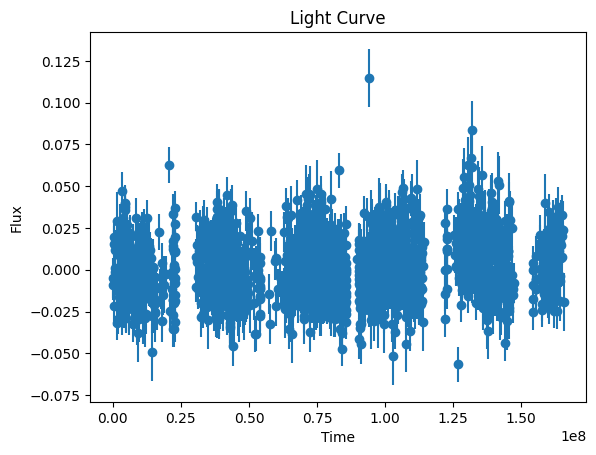

In [ ]:
data_file = '../data/tydy.csv'
data = pd.read_csv(data_file, header=None).to_numpy()
print(data)
times = data[:, 0]
flux = data[:, 1]
flux_err = data[:, 2]

plt.figure()
plt.errorbar(times, flux, yerr=flux_err, fmt='o')
plt.xlabel('Time')
plt.ylabel('Flux')
plt.title('Light Curve')
plt.show()

fgrid_file = '../data/fgrid.csv'
fgrid = pd.read_csv(fgrid_file, header=None).to_numpy().flatten()

fpw_pgram = fpw.run_fpw(times, flux, flux_err, fgrid, 20)

In [ ]:
#Make the FPW pgram into a dataframe and save it as a csv
fpw_df = pd.DataFrame(fpw_pgram)
fpw_df.to_csv('../data/CPU_periodogram.csv', index=False, header=False)

[44.66485365 47.56414758 42.37941599 43.94024443 48.09821763 41.62355904
 45.49955609 44.68953271 47.2135424  41.14752341]


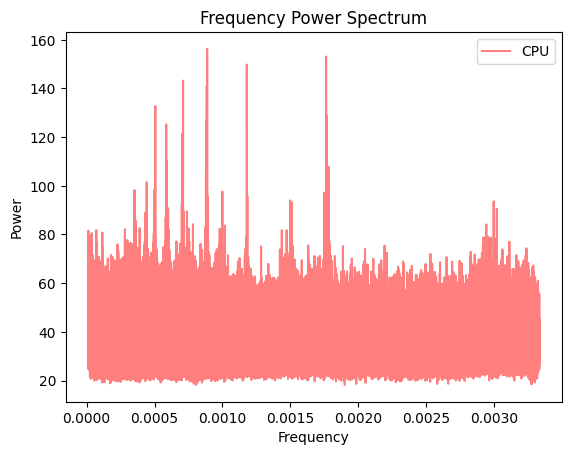

In [ ]:
print(fpw_pgram[0:10])

fgrid_file = '../data/fgrid.csv'
fgrid = pd.read_csv(fgrid_file, header=None).to_numpy().flatten()

cpu_pgram_file = '../data/CPU_periodogram.csv'
cpu_pgram = pd.read_csv(cpu_pgram_file, header=None).to_numpy().flatten()

# gpu_pgram_file = './data/GPU_periodogram.csv'
# gpu_pgram = pd.read_csv(gpu_pgram_file, header=None).to_numpy().flatten()

# residuals = gpu_pgram - cpu_pgram

plt.figure()
# plt.plot(fgrid, gpu_pgram, label='GPU', color='blue', alpha=0.5)
plt.plot(fgrid, cpu_pgram, label='CPU', color='red', alpha=0.5)
# plt.plot(fgrid, residuals, label='GPU - CPU', color='green', alpha=0.5)
plt.legend()
plt.xlabel('Frequency')
plt.ylabel('Power')
plt.title('Frequency Power Spectrum')
plt.show()

# plt.figure()
# plt.hist(residuals, bins=100)
# plt.xlabel('Residuals')
# plt.ylabel('Count')
# plt.title('Residuals Histogram')
# plt.show()